## Proyecto 1: Análisis de señales ECG y detección de arritmias 
## Proyecto 2026-02 


## Presentado por:

 Esteban Garcia Otalvaro
 
 Fabian Andres Posso

Bioseñales y Sistemas — Bioingeniería, Universidad de Antioquia — 2026-02

Base de datos: Chapman University & Shaoxing People's Hospital (Zheng et al., 2020), disponible en Figshare: https://figshare.com/collections/ChapmanECG/4560497/1

In [17]:
# ==========================================
# 1. LIBRERÍAS BASE Y VISUALIZACIÓN
# ==========================================

# Importa la librería para manejo de arreglos y cálculos numéricos matemáticos.
import numpy as numpy

# Importa Pandas, la herramienta principal para manipular y analizar los datos clínicos (DataFrames).
import pandas as pd

# Importa el módulo clásico de Python para crear gráficas.
import matplotlib.pyplot as plt

# Importa Seaborn, que mejora el diseño y estética de las gráficas estadísticas.
import seaborn as sns

# Importa el módulo del sistema operativo para navegar por directorios y construir rutas seguras.
import os

# Herramienta de dibujo para crear cajas con bordes redondeados en las visualizaciones.
from matplotlib.patches import FancyBboxPatch


# ==========================================
# 2. HERRAMIENTAS ESTADÍSTICAS (SCIPY)
# ==========================================

# Pruebas para evaluar la independencia entre variables categóricas (ej. cruzar Género vs Tipo de Arritmia).
from scipy.stats import chi2_contingency, fisher_exact

# Kruskal-Wallis para comparar medianas sin distribución normal, y skew para calcular la asimetría.
from scipy.stats import kruskal, skew

# Importa la distribución estadística Chi-cuadrado pura, renombrada como dist_chi2 para evitar conflictos de nombres.
from scipy.stats import chi2 as dist_chi2


# ==========================================
# 3. DEFINICIÓN DE RUTAS Y CONSTANTES
# ==========================================

# Ruta local absoluta de tu archivo Excel. La 'r' (raw string) evita errores con las barras invertidas '\' de Windows.
ruta_diagnostics = r"C:\Users\LENOVO\OneDrive - Universidad de Antioquia\Escritorio\BIOSEÑALES Y SISTEMAS\Laboratorio\ECGDataDenoised\Diagnostics.xlsx"

# Construye la ruta de la carpeta de señales uniendo las partes de forma compatible con cualquier sistema operativo.
CARPETA_ECG = os.path.join("ChapmanECG", "ECGDataDenoised")

# Define la frecuencia de muestreo constante (500 datos registrados por segundo).
FS = 500


# ==========================================
# 4. CONFIGURACIÓN GLOBAL Y VERIFICACIÓN
# ==========================================

# Ajusta la configuración de las gráficas para que tengan mayor nitidez (110 DPI) y tamaño de letra 10.
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Imprime la ruta de la carpeta actual donde se está ejecutando este Jupyter Notebook.
print("Carpeta del notebook:       ", os.getcwd())

# Verifica si el archivo Excel realmente existe en la ruta dada (imprime True o False).
print("Diagnostics.xlsx encontrado:", os.path.exists(ruta_diagnostics))

# Verifica si la carpeta de señales existe en el sistema (imprime True o False).
print("Carpeta ECG encontrada:     ", os.path.isdir(CARPETA_ECG))

Carpeta del notebook:        c:\Users\LENOVO\OneDrive - Universidad de Antioquia\Escritorio\BIOSEÑALES Y SISTEMAS\Laboratorio\Biose-ales-Esteban-Garcia\Proyecto Semestre
Diagnostics.xlsx encontrado: True
Carpeta ECG encontrada:      False


## 1.Diagramas de flujo y metodología de los 3 artículos

1.1. An Arrhythmia classification approach via deep learning using single-lead ECG without QRS wave detection.

1.2. Optimal Multi-Stage Arrhythmia Classification Approach

1.3. Prediction of atrial fibrillation from at-home single-lead ECG signals without arrhythmias

## 2.Análisis estadístico generalizado y preguntas informativas del Dataset

2. Cargar el archivo Diagnostics.xlsx y realizar un análisis estadístico general de los datos. Desde la información en la base de datos resolver las siguientes preguntas 

In [6]:

df = pd.read_excel(ruta_diagnostics)
# Observación preliminar de las variables y estructura del dataset
df.describe()



,PatientAge,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
count,10646.000000,10646.000000,10646.00000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000
mean,59.186831,84.136107,92.57787,90.989292,384.150855,434.154048,39.620609,44.637704,13.839470,219.260567,264.755213,411.335995
std,18.030019,34.455349,60.09394,17.479540,59.226289,39.354182,41.212648,57.478092,5.676339,6.410413,8.362120,29.777404
min,4.000000,34.000000,0.00000,18.000000,114.000000,219.000000,-89.000000,-89.000000,5.000000,159.000000,249.000000,281.000000
25%,49.000000,57.000000,57.00000,80.000000,344.000000,408.000000,14.000000,19.000000,9.000000,216.000000,259.000000,392.000000
50%,62.000000,73.000000,72.00000,88.000000,390.000000,430.000000,46.000000,42.000000,12.000000,219.000000,264.000000,414.000000
75%,72.000000,104.000000,106.00000,98.000000,426.000000,456.000000,68.000000,62.000000,17.000000,224.000000,268.000000,432.000000
max,98.000000,263.000000,535.00000,256.000000,736.000000,760.000000,270.000000,270.000000,40.000000,240.000000,331.000000,582.000000


In [7]:
df.groupby(by=["Rhythm"]).describe()

PatientAge                                                       \
            count       mean        std   min    25%   50%   75%   max   
Rhythm                                                                   
AF          445.0  71.065169  13.497673  21.0  63.00  72.0  81.0  97.0   
AFIB       1780.0  73.359551  11.137343  30.0  67.00  75.0  82.0  98.0   
AT          121.0  65.719008  19.300787   8.0  60.00  71.0  77.0  94.0   
AVNRT        16.0  57.875000  17.335417  27.0  51.00  59.0  66.0  84.0   
AVRT          8.0  57.500000  16.835337  25.0  47.75  62.5  67.0  77.0   
SA          399.0  34.746867  23.029446   4.0  14.50  29.0  52.5  93.0   
SAAWR         7.0  51.142857  31.829905  15.0  22.50  49.0  81.0  87.0   
SB         3889.0  58.339676  13.952579  10.0  50.00  60.0  68.0  98.0   
SR         1826.0  54.352136  16.331977   4.0  44.00  55.0  66.0  95.0   
ST         1568.0  54.565051  21.060029   4.0  40.00  57.0  70.0  96.0   
SVT         587.0  55.623509  18.527343   4.0  42.00  56.0  69.0  96.0   

       VentricularRate              ... QOffset        TOffset              \
                 count        mean  ...     75%    max   count        mean   
Rhythm                              ...                                      
AF               445.0  114.577528  ...  272.00  314.0   445.0  392.907865   
AFIB            1780.0   95.489326  ...  269.00  311.0  1780.0  402.439888   
AT               121.0  116.438017  ...  267.00  294.0   121.0  387.388430   
AVNRT             16.0  172.250000  ...  271.00  316.0    16.0  359.062500   
AVRT               8.0  171.000000  ...  266.75  274.0     8.0  358.125000   
SA               399.0   72.922306  ...  266.50  299.0   399.0  411.834586   
SAAWR              7.0   64.428571  ...  266.00  274.0     7.0  423.428571   
SB              3889.0   55.022885  ...  269.00  314.0  3889.0  435.605554   
SR              1826.0   75.748083  ...  267.00  311.0  1826.0  413.105148   
ST              1568.0  112.157526  ...  266.00  303.0  1568.0  386.538265   
SVT              587.0  168.367973  ...  271.00  331.0   587.0  358.831346   

                                                       
              std    min    25%    50%     75%    max  
Rhythm                                                 
AF      34.783087  302.0  369.0  389.0  412.00  537.0  
AFIB    26.553652  307.0  385.0  403.0  420.00  562.0  
AT      25.048743  323.0  372.0  387.0  403.00  490.0  
AVNRT   10.009787  334.0  355.5  359.5  363.25  381.0  
AVRT    26.351674  318.0  338.0  364.0  378.25  390.0  
SA      15.496724  376.0  400.5  411.0  421.00  466.0  
SAAWR   15.576233  406.0  414.0  421.0  428.00  453.0  
SB      17.177428  385.0  424.0  434.0  445.00  582.0  
SR      14.925198  370.0  403.0  413.0  423.00  494.0  
ST      15.636704  328.0  377.0  387.0  395.00  559.0  
SVT     19.553825  281.0  347.0  359.0  371.00  475.0  

[11 rows x 96 columns]

¿Qué tipo de arritmias son más prevalentes? 

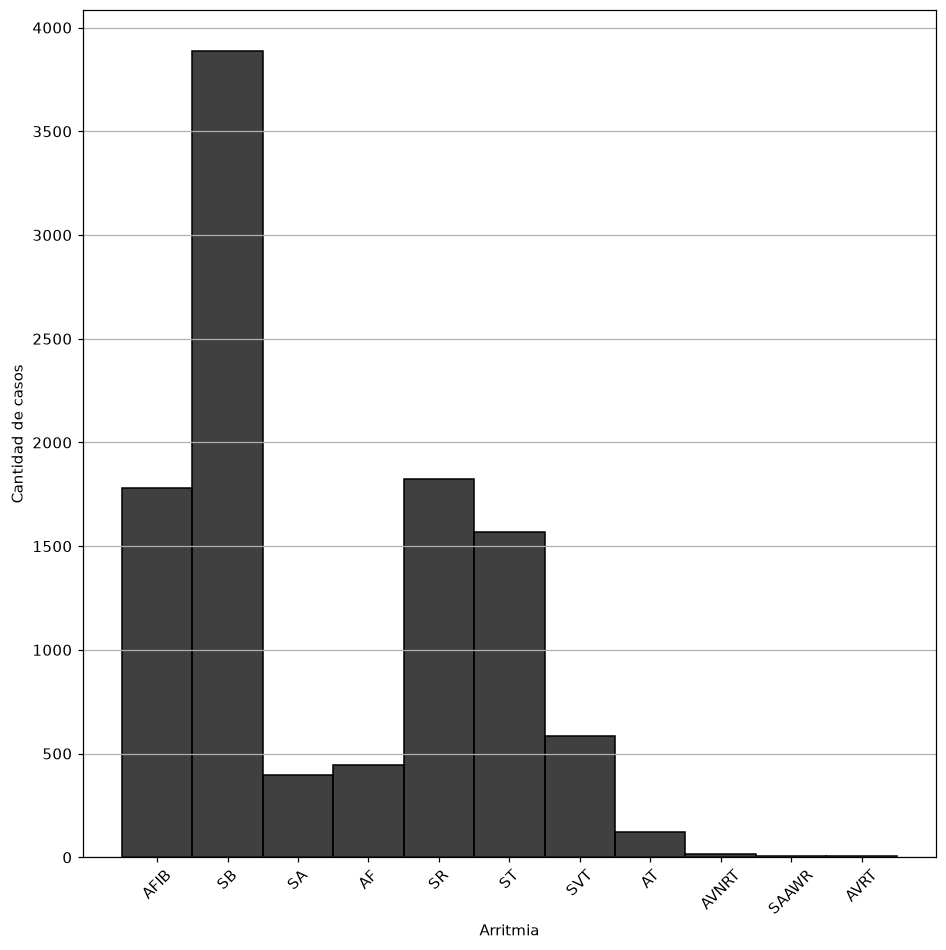

In [8]:
plt.figure(figsize=(10, 10))
sns.histplot(df['Rhythm'], bins=10, kde=False, color='black')

plt.ylabel('Cantidad de casos')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

¿Hay arritmias que son más prevalentes para un género específico?

In [9]:
df['Gender'].value_counts()

Gender
MALE      5956
FEMALE    4690
Name: count, dtype: int64

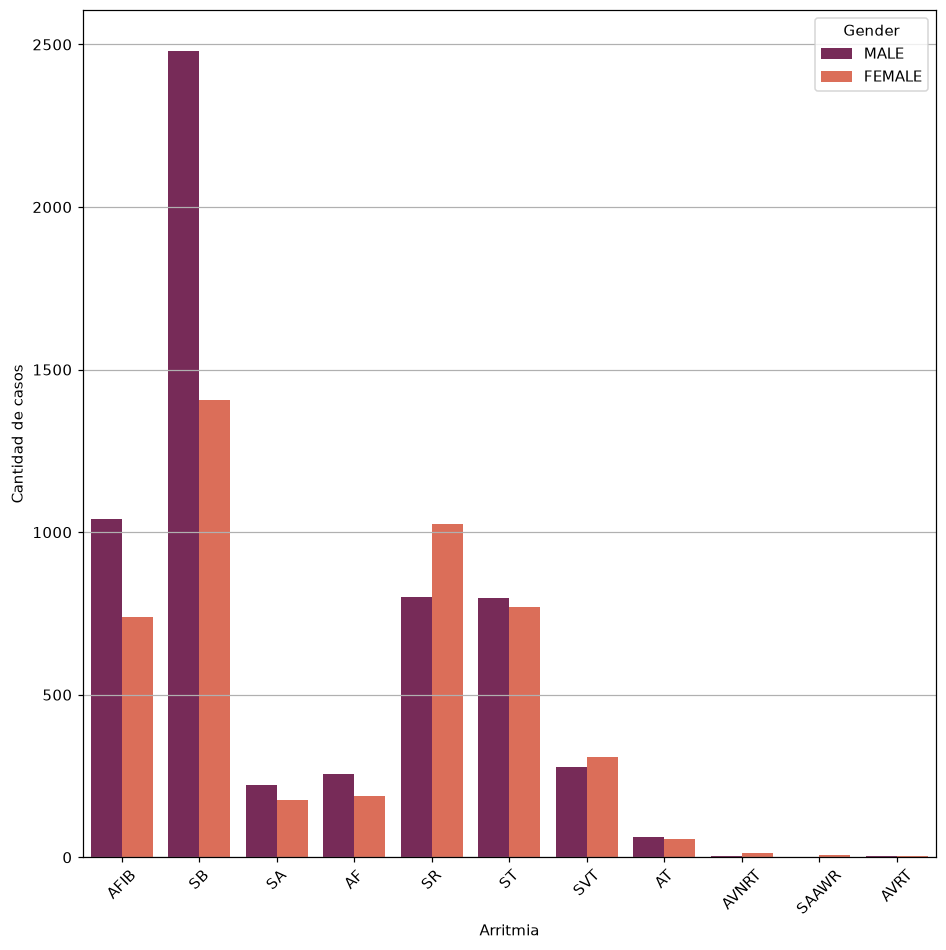

In [16]:
plt.figure(figsize=(10, 10))
sns.countplot(data=df, x='Rhythm', hue='Gender', palette='rocket')
plt.ylabel('Cantidad de casos')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12992\2861780615.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Rhythm', y='PatientAge', palette='rocket')


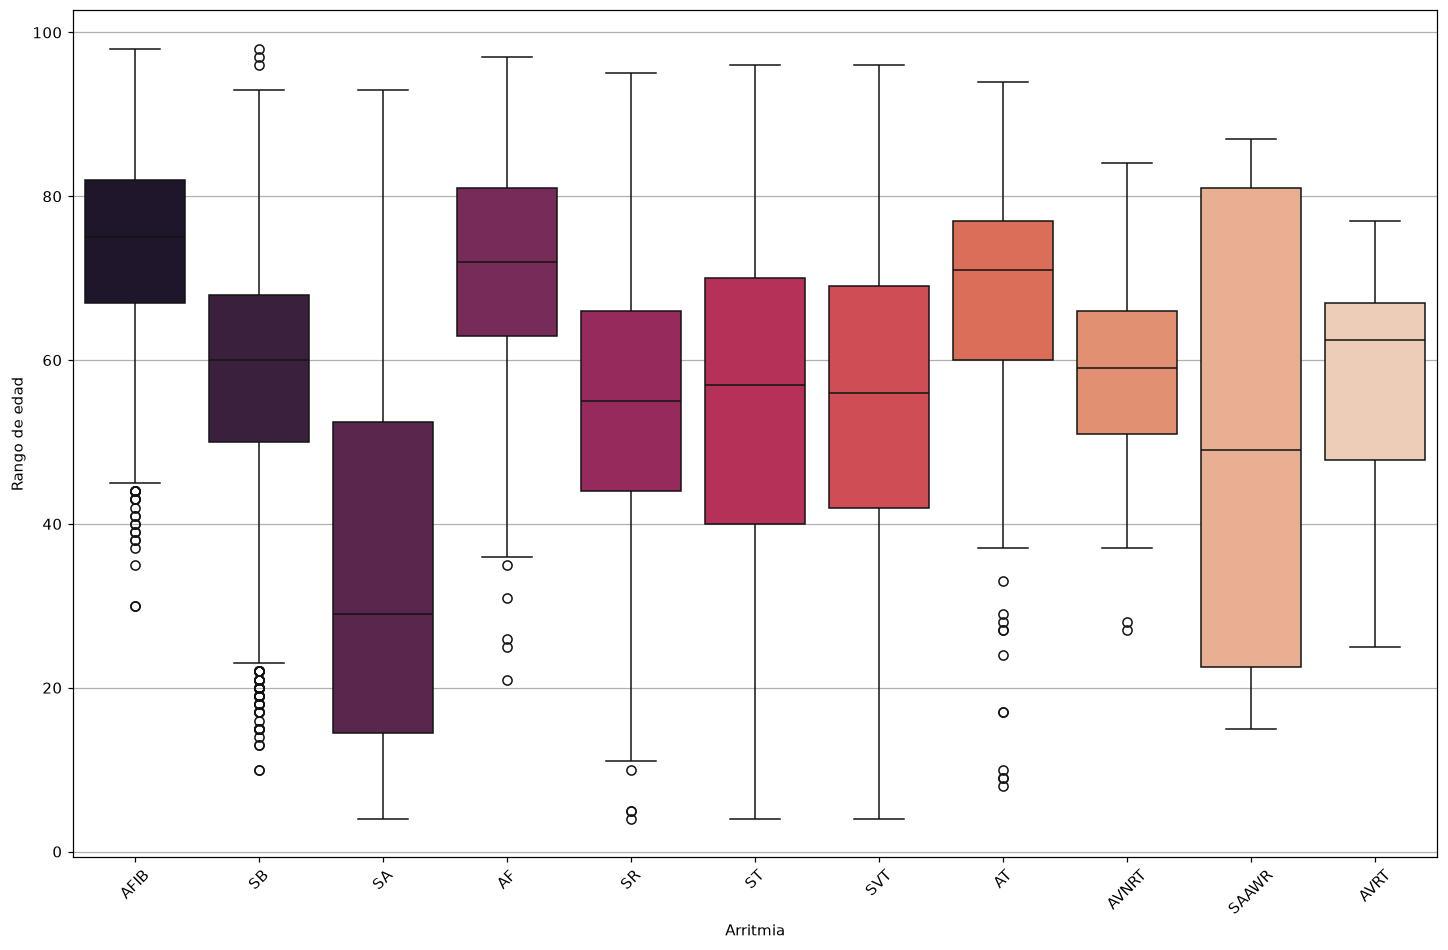

In [11]:
plt.figure(figsize=(16, 10))
sns.boxplot(data=df, x='Rhythm', y='PatientAge', palette='rocket')
plt.ylabel('Rango de edad')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

¿Hay arritmias que son más prevalentes para una edad?

<Axes: xlabel='PatientAge', ylabel='Count'>

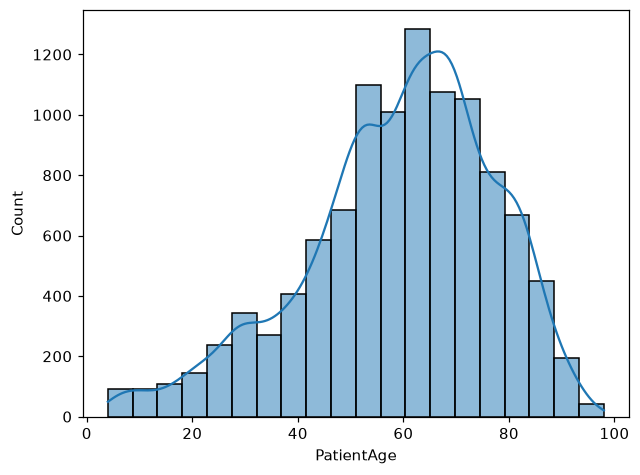

In [12]:
df['PatientAge'].describe()
sns.histplot(df['PatientAge'], bins=20, kde=True)

<Axes: xlabel='PatientAge', ylabel='Count'>

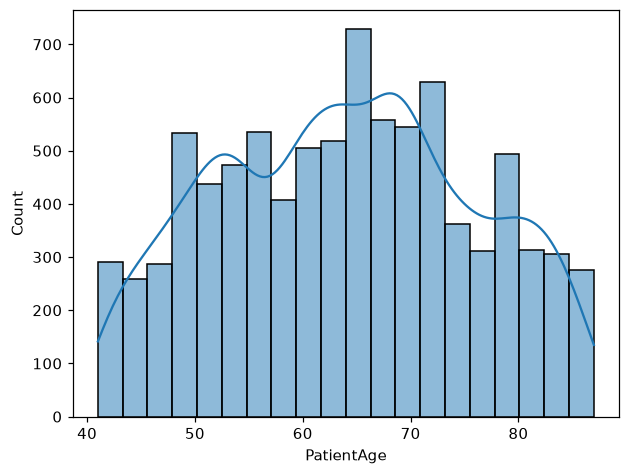

In [13]:
df_filtrado = df[(df['PatientAge'] >= 41) & (df['PatientAge'] <= 87)]
df_filtrado.describe()
sns.histplot(df_filtrado['PatientAge'], bins=20, kde=True)

Los algoritmos de aprendizaje se basan en usar la mayor cantidad de datos posibles que sean comparables, ¿Qué rango de edades y arritmias de la base de datos entregada considera que debe usar para entrenar algoritmos de aprendizaje? 

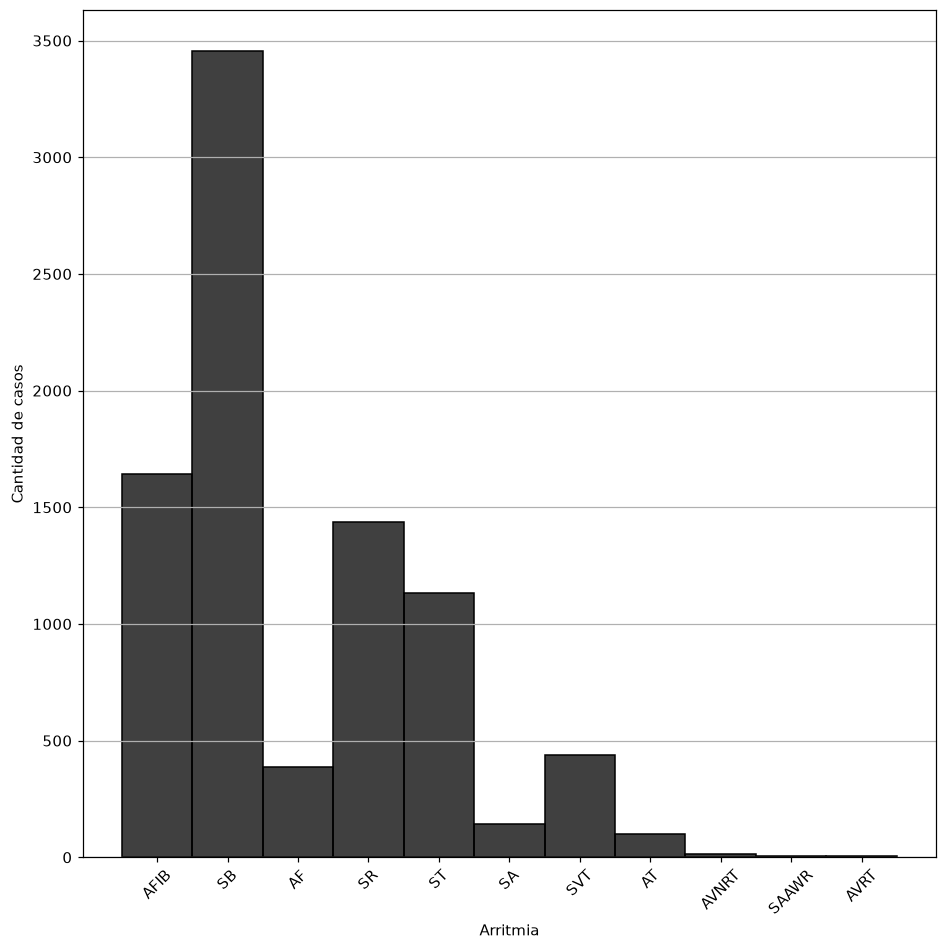

In [14]:
plt.figure(figsize=(10, 10))
sns.histplot(df_filtrado['Rhythm'], bins=10, kde=False, color='black')
plt.ylabel('Cantidad de casos')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12992\4103379746.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtrado, x='Rhythm', y='PatientAge', palette='rocket')


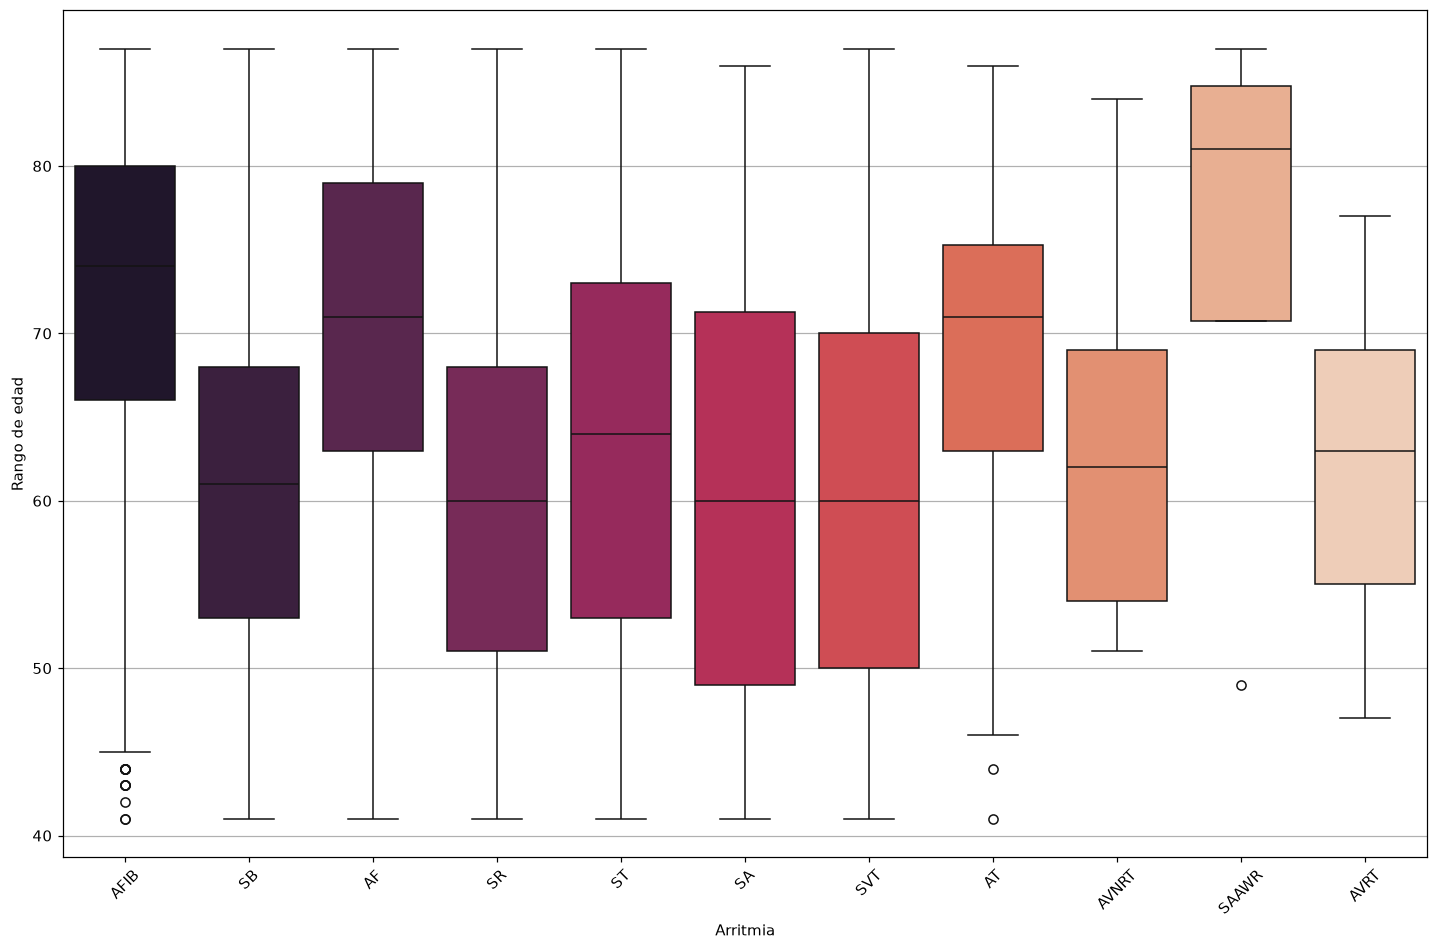

In [15]:
plt.figure(figsize=(16, 10))
sns.boxplot(data=df_filtrado, x='Rhythm', y='PatientAge', palette='rocket')
plt.ylabel('Rango de edad')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

¿Hay coincidencia entre lo encontrado en literatura y lo encontrado en la base de datos? 

 ¿Qué otros análisis propone desde la base de datos?

Con base en el análisis descriptivo del punto anterior, seleccionar un subconjunto de datos para trabajar en los siguientes análisis. 
3. Programar las fórmulas 1 al 4 que se encuentran en el artículo (15%). 

Consultar que significado y utilidad del biespectro (5%) https://arxiv.org/pdf/1809.08451 

## 3. Fórmulas del artículo y significado-utilidad del biespectro

3. Programar las fórmulas 1 al 4 que se encuentran en el artículo (15%). 
Consultar que significado y utilidad del biespectro (5%)

## 4.Frecuencia de máxima potencia de las señales

4. Para cada señal extraer la frecuencia que contiene la máxima potencia 
(15%). 

## 5.Suma de frecuencias significativas de cada señal (sFSB)

5. Para cada señal, sumar el número de frecuencias que son significativas para bicoherencia (aquellas con un valor superior a $\sqrt{\dfrac{9.2}{2 \cdot N}}$ (10 %)).

## 6. Rutina aplicada al Dataframe para el registro, tipo de patología, la fMP y frecuencias significativas

6. Crear una rutina que aplique sobre todos los archivos de la base de datos las rutinas 3 al 5 y almacene los resultados en un dataframe donde se pueda registrar el registro, tipo de patología y la frecuencia de máxima potencia (fMP) y suma de frecuencias significativas en bicoherencia (sFSB) (10 %)

<div align="center">

| Registro | Estado | fMP | sFSB |
|:--------:|:------:|:---:|:----:|
|          |        |     |      |
|          |        |     |      |

</div>

## 7. Estadística descriptiva para cada arritmia

7. Para las señales de análisis del punto 2 aplicar las rutinas del punto 3 al 
5  y  hacer  un  informe  que  permita  evidenciar  las  diferencias  entre  las 
señales las diferentes arritmias utilizando las herramientas de estadística 
descriptiva (5%). 

## 8. Diferencia estadística a través de pruebas estadísticas

8. Indicar  si  hay  o  no  diferencias  estadísticas  entre  las  características 
espectrales del punto 4 y 5 para las poblaciones de estudio (5%)

## 9. Análisis de resultados y conclusiones

9. Hacer un informe con todos los puntos anteriores. El informe debe 
incluir análisis de resultados y conclusiones (15%). Trabajo sin sustentar 
no se califica